# week04-homework-api-data

**第四周作业：选择 1 家上市公司并结合 tushare 获取数据进行分析**

- 自由选择 1 家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用 tushare 获取与该公司相关的数据（股市价格、财务、宏观等均可）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。

> 提交要求：把本文件命名为 `week04-homework-api-data_学号_姓名.ipynb` 后在线提交。
> 本文档包含四部分：**公司名称与基本简介**、**研究问题题目及其内涵介绍**、**数据采集**、**数据分析与问题解答**，并附**研究结论与经验总结**。

# 第一部分：公司名称与基本简介

## 公司概况

- **公司全称**：贵州茅台酒股份有限公司
- **股票代码**：600519.SH（上交所主板）
- **所属行业**：食品饮料 — 白酒（高端白酒）
- **上市日期**：2001-08-27
- **主营业务**：茅台酒及系列酒的生产与销售，核心产品为飞天茅台（53%vol）。
- **市场地位**：A 股“核心资产”代表之一，凭借极强的品牌护城河、超高毛利率（长期 90% 上下）与稳定 ROE（长期 30% 上下），长期被视为价值投资标杆。

下面用 tushare `stock_basic` 接口拉取该公司的权威基础信息作为佐证。

In [1]:
import tushare as ts
import pandas as pd

pro = ts.pro_api()  # 已在下方“数据采集”cell 完成 set_token
info = pro.stock_basic(
    ts_code="600519.SH",
    fields="ts_code,symbol,name,area,industry,market,list_date,list_status"
)
info

,ts_code,symbol,name,area,industry,market,list_date,list_status
0,600519.SH,600519,贵州茅台,贵州,白酒,主板,20010827,L


# 第二部分：研究问题题目及其内涵介绍

## 研究问题

> **贵州茅台股价长期大幅上涨，背后究竟是“业绩驱动”还是“估值驱动”？其估值相对历史、相对市场（沪深300）又处于什么位置？**

## 问题内涵

1. **可分解的框架**：股价长期表现可拆解为 `价格 = 每股收益(EPS) × 市盈率(PE)`。因此股价涨跌可被清晰地拆成“盈利增长”与“估值变化”两条主线。
2. **业绩驱动 vs 估值驱动的意义**：若上涨主要由 EPS 增长驱动，说明市场在为真实业绩买单，具备基本面支撑；若主要由 PE 扩张驱动，则更多反映风险偏好与情绪，估值回调风险更大。
3. **需要双重校验**：仅看个股涨幅会被“牛市贝塔”掩盖。必须与基准（沪深300）对比看**超额收益**，并用 PE 的**历史分位**判断当前贵不贵。
4. **数据方案**：用 tushare 获取茅台 2015–2026 年的日线行情、每日估值（PE/市值）、季度财务指标（ROE/毛利率/营收同比）以及沪深300指数行情，用数据回答上述问题。

# 第三部分：数据采集

> 按老师要求，tushare token 直接写入代码，便于批改。

In [2]:
import tushare as ts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import os

# 中文字体（避免图表中文变方块）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
matplotlib.rcParams['figure.dpi'] = 110
%matplotlib inline

# 为了批改方便，tushare token 直接放到代码中
TOKEN = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(TOKEN)
pro = ts.pro_api()
print("tushare 初始化完成，pro 接口就绪。")

tushare 初始化完成，pro 接口就绪。


In [3]:
# 参数设置
TS_CODE = "600519.SH"   # 贵州茅台
IDX_CODE = "000300.SH"  # 沪深300 指数
START = "20150101"
END = "20260930"

# 1) 日线行情（开高低收、成交量、成交额）
df_daily = pro.daily(ts_code=TS_CODE, start_date=START, end_date=END)
df_daily['trade_date'] = pd.to_datetime(df_daily['trade_date'])
df_daily = df_daily.sort_values('trade_date').set_index('trade_date')
print("日线行情:", df_daily.shape)
df_daily.head()

日线行情: (2855, 10)


,ts_code,open,high,low,close,pre_close,change,pct_chg,vol,amount
trade_date,,,,,,,,,,
2015-01-05,600519.SH,189.62,204.24,188.69,202.52,189.62,12.90,6.80,94515.17,1875063.136
2015-01-06,600519.SH,200.00,202.56,196.02,197.83,202.52,-4.69,-2.32,55020.01,1094977.375
2015-01-07,600519.SH,196.04,199.50,189.99,192.94,197.83,-4.89,-2.47,54797.84,1063925.641
2015-01-08,600519.SH,194.00,194.52,190.14,191.76,192.94,-1.18,-0.61,40525.30,777874.670
2015-01-09,600519.SH,190.40,195.77,190.11,190.31,191.76,-1.45,-0.76,53982.20,1039955.153


In [4]:
# 2) 每日指标（估值：PE / PE(TTM) / PS / 总市值 / 流通市值）
df_basic = pro.daily_basic(
    ts_code=TS_CODE, start_date=START, end_date=END,
    fields="trade_date,close,pe,pe_ttm,ps,ps_ttm,total_mv,circ_mv"
)
df_basic['trade_date'] = pd.to_datetime(df_basic['trade_date'])
df_basic = df_basic.sort_values('trade_date').set_index('trade_date')
print("每日估值:", df_basic.shape)
df_basic.head()

每日估值: (2855, 7)


,close,pe,pe_ttm,ps,ps_ttm,total_mv,circ_mv
trade_date,,,,,,,
2015-01-05,202.52,15.2793,15.6694,7.4794,7.5324,2.312774e+07,2.312774e+07
2015-01-06,197.83,14.9255,15.3066,7.3062,7.3580,2.259215e+07,2.259215e+07
2015-01-07,192.94,14.5565,14.9282,7.1256,7.1761,2.203371e+07,2.203371e+07
2015-01-08,191.76,14.4675,14.8369,7.0820,7.1322,2.189895e+07,2.189895e+07
2015-01-09,190.31,14.3581,14.7247,7.0285,7.0783,2.173336e+07,2.173336e+07


In [5]:
# 3) 财务指标（ROE / 毛利率 / 净利率 / 营收同比 / 净利润同比 / EPS）
df_fina = pro.fina_indicator(
    ts_code=TS_CODE, start_date="20140101", end_date=END,
    fields="end_date,roe,grossprofit_margin,netprofit_margin,or_yoy,profit_yoy,eps,dt_eps"
)
df_fina['end_date'] = pd.to_datetime(df_fina['end_date'])
df_fina = df_fina.sort_values('end_date')
print("财务指标:", df_fina.shape)
df_fina.tail()

财务指标: (90, 7)


,end_date,roe,grossprofit_margin,netprofit_margin,or_yoy,eps,dt_eps
4,2025-06-30,19.2486,91.2993,52.5641,9.1032,36.18,36.18
3,2025-09-30,26.3688,91.2934,52.0801,6.3569,51.53,51.53
2,2025-12-31,34.4620,91.1796,50.5279,-1.2060,65.66,65.66
1,2026-03-31,10.5687,89.7592,52.2245,6.5380,21.76,21.76
0,2026-06-30,17.9543,89.5552,50.7516,1.4699,35.57,35.57


In [6]:
# 4) 利润表（营收 / 净利润 / 营业成本）
df_income = pro.income(
    ts_code=TS_CODE, start_date="20140101", end_date=END,
    fields="end_date,revenue,n_income,total_cogs"
)
df_income['end_date'] = pd.to_datetime(df_income['end_date'])
df_income = df_income.sort_values('end_date')
print("利润表:", df_income.shape)
df_income.tail()

利润表: (67, 4)


,end_date,revenue,n_income,total_cogs
4,2025-12-31,1.688381e+11,8.531032e+10,5.735358e+10
3,2026-03-31,5.390925e+10,2.815383e+10,1.716636e+10
2,2026-03-31,5.390925e+10,2.815383e+10,1.716636e+10
1,2026-06-30,9.070326e+10,4.603333e+10,3.091357e+10
0,2026-06-30,9.070326e+10,4.603333e+10,3.091357e+10


In [7]:
# 5) 沪深300 指数行情（作为市场基准）
df_idx = pro.index_daily(ts_code=IDX_CODE, start_date=START, end_date=END)
df_idx['trade_date'] = pd.to_datetime(df_idx['trade_date'])
df_idx = df_idx.sort_values('trade_date').set_index('trade_date')
print("沪深300:", df_idx.shape)
df_idx.head()

沪深300: (2855, 10)


,ts_code,close,open,high,low,pre_close,change,pct_chg,vol,amount
trade_date,,,,,,,,,,
2015-01-05,000300.SH,3641.541,3566.089,3669.042,3551.510,3533.705,107.836,3.0516,451198098.0,5.198498e+08
2015-01-06,000300.SH,3641.059,3608.428,3683.226,3587.231,3641.541,-0.482,-0.0132,420962185.0,4.985296e+08
2015-01-07,000300.SH,3643.790,3620.924,3671.190,3601.698,3641.059,2.731,0.0750,320191232.0,3.987317e+08
2015-01-08,000300.SH,3559.259,3650.073,3659.945,3552.100,3643.790,-84.531,-2.3199,295003045.0,3.558320e+08
2015-01-09,000300.SH,3546.723,3547.574,3689.753,3536.395,3559.259,-12.536,-0.3522,349982672.0,4.302106e+08


In [8]:
# 6) 合并行情与估值，并推导隐含 EPS(TTM) = 收盘价 / PE(TTM)
price = pd.concat([
    df_daily[['close', 'open', 'high', 'low', 'vol', 'amount']],
    df_basic[['pe', 'pe_ttm', 'ps_ttm', 'total_mv', 'circ_mv']]
], axis=1)
price['eps_ttm'] = price['close'] / price['pe_ttm']   # 由 价格=PE×EPS 反推
price = price.dropna(subset=['pe_ttm'])
print("合并后行情+估值:", price.shape)
price.head()

# 保存为本地 CSV，便于复现
os.makedirs("data", exist_ok=True)
price.to_csv("data/maotai_price.csv")
df_fina.to_csv("data/maotai_fina.csv")
df_idx.to_csv("data/hs300.csv")
print("数据已保存到 data/ 目录")

合并后行情+估值: (2855, 12)
数据已保存到 data/ 目录


# 第四部分：数据分析过程

分析主线：
1. 看股价长期走势与估值（PE）走势及历史分位；
2. 与沪深300 做净值对比，量化**超额收益**；
3. 用 `价格 = PE × EPS` 把股价涨幅**分解为盈利贡献 vs 估值贡献**；
4. 统计风险收益特征（年化收益、波动、最大回撤、夏普）；
5. 看基本面（ROE / 毛利率）是否支撑高估值。

In [9]:
# 预处理：计算日收益率，并对齐到茅台与沪深300的共同交易日
price['ret'] = price['close'].pct_change()
df_idx['ret'] = df_idx['close'].pct_change()

common = price.index.intersection(df_idx.index)
m_ret = pd.DataFrame({
    'maotai': price.loc[common, 'ret'],
    'hs300': df_idx.loc[common, 'ret'],
}).dropna()
print("共同交易日样本:", m_ret.shape)
m_ret.head()

共同交易日样本: (2854, 2)


,maotai,hs300
trade_date,,
2015-01-06,-0.023158,-0.000132
2015-01-07,-0.024718,0.000750
2015-01-08,-0.006116,-0.023199
2015-01-09,-0.007562,-0.003522
2015-01-12,-0.020388,-0.009346


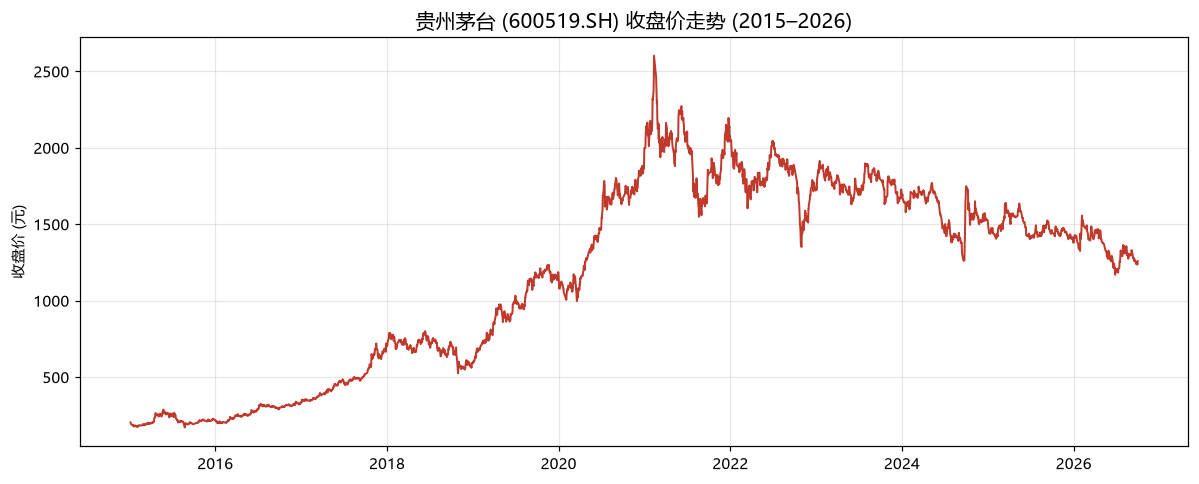

In [10]:
# 图1：茅台收盘价长期走势
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(price.index, price['close'], color='#c0392b', lw=1.3)
ax.set_title('贵州茅台 (600519.SH) 收盘价走势 (2015–2026)', fontsize=13)
ax.set_ylabel('收盘价 (元)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

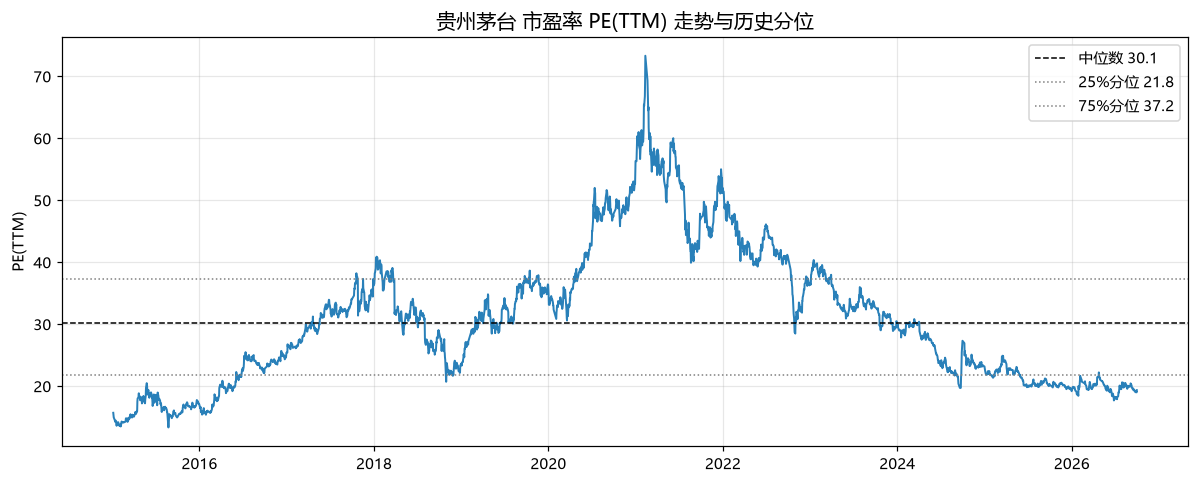

当前 PE(TTM) = 19.3，处于历史 12% 分位（越低越便宜）


In [11]:
# 图2：PE(TTM) 走势 + 历史分位参考线
pe = price['pe_ttm'].dropna()
med = pe.median(); p25 = pe.quantile(0.25); p75 = pe.quantile(0.75)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(pe.index, pe.values, color='#2980b9', lw=1.3)
ax.axhline(med, color='black', ls='--', lw=1, label=f'中位数 {med:.1f}')
ax.axhline(p25, color='gray', ls=':', lw=1, label=f'25%分位 {p25:.1f}')
ax.axhline(p75, color='gray', ls=':', lw=1, label=f'75%分位 {p75:.1f}')
ax.set_title('贵州茅台 市盈率 PE(TTM) 走势与历史分位', fontsize=13)
ax.set_ylabel('PE(TTM)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

cur = pe.iloc[-1]
print(f"当前 PE(TTM) = {cur:.1f}，处于历史 {(pe < cur).mean()*100:.0f}% 分位（越低越便宜）")

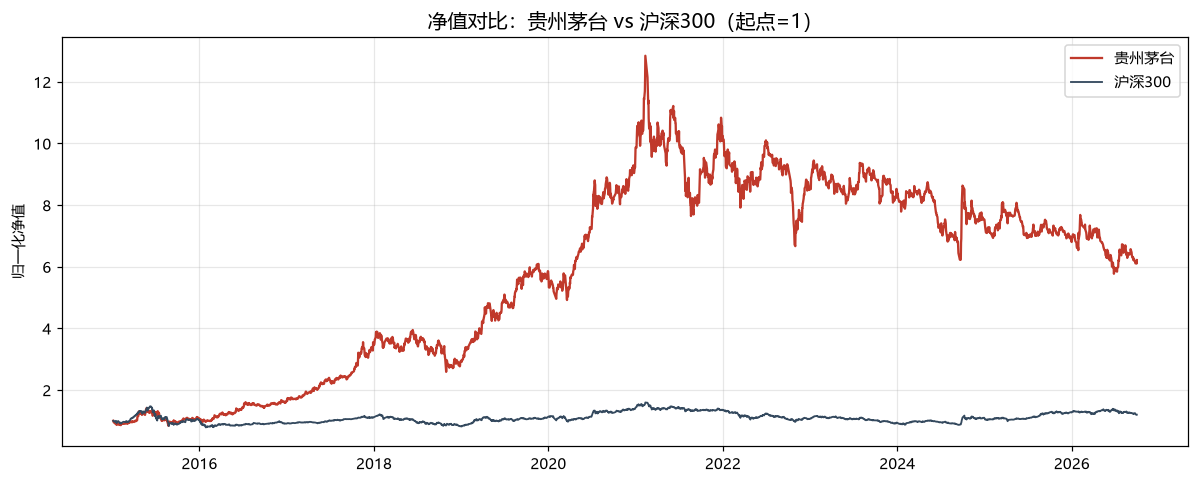

区间累计涨幅  茅台: 521.5%   沪深300: 19.7%   超额收益: 501.8%


In [12]:
# 图3：茅台 vs 沪深300 归一化净值（起点=1），看超额收益
nv = pd.DataFrame({
    '茅台': price['close'] / price['close'].iloc[0],
    '沪深300': df_idx['close'] / df_idx['close'].iloc[0],
})
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(nv.index, nv['茅台'], color='#c0392b', lw=1.5, label='贵州茅台')
ax.plot(nv.index, nv['沪深300'], color='#34495e', lw=1.2, label='沪深300')
ax.set_title('净值对比：贵州茅台 vs 沪深300（起点=1）', fontsize=13)
ax.set_ylabel('归一化净值')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

total_ret_m = nv['茅台'].iloc[-1] - 1
total_ret_i = nv['沪深300'].iloc[-1] - 1
print(f"区间累计涨幅  茅台: {total_ret_m:.1%}   沪深300: {total_ret_i:.1%}   超额收益: {total_ret_m - total_ret_i:.1%}")

In [13]:
# 收益归因分解：价格 = PE × EPS（按年度快照）
tmp = price.copy()
tmp['year'] = tmp.index.year
snap = tmp.groupby('year').last()[['close', 'pe_ttm']].copy()
snap['eps_ttm'] = snap['close'] / snap['pe_ttm']
snap = snap.sort_index()

# 逐年变化：price_ret ≈ eps_ret + pe_ret + eps_ret*pe_ret（恒等式验证）
snap['price_ret'] = snap['close'].pct_change()
snap['eps_ret'] = snap['eps_ttm'].pct_change()
snap['pe_ret'] = snap['pe_ttm'].pct_change()
snap['check'] = (1 + snap['eps_ret']) * (1 + snap['pe_ret']) - 1

disp = snap[['close', 'pe_ttm', 'eps_ttm', 'price_ret', 'eps_ret', 'pe_ret', 'check']].round(3)
disp

,close,pe_ttm,eps_ttm,price_ret,eps_ret,pe_ret,check
year,,,,,,,
2015,218.19,17.044,12.801,NaN,NaN,NaN,NaN
2016,334.15,25.372,13.170,0.531,0.029,0.489,0.531
2017,697.49,36.151,19.294,1.087,0.465,0.425,1.087
2018,590.01,23.286,25.338,-0.154,0.313,-0.356,-0.154
2019,1183.00,36.312,32.578,1.005,0.286,0.559,1.005
2020,1998.00,56.302,35.487,0.689,0.089,0.550,0.689
2021,2050.00,51.364,39.911,0.026,0.125,-0.088,0.026
2022,1727.00,36.404,47.440,-0.158,0.189,-0.291,-0.158
2023,1726.00,30.455,56.673,-0.001,0.195,-0.163,-0.001


In [14]:
# 累计分解：以 2015 年为基期
base_y = 2015
base = snap.loc[base_y]
eps_mult = snap['eps_ttm'] / base['eps_ttm']
pe_mult = snap['pe_ttm'] / base['pe_ttm']
price_mult = snap['close'] / base['close']

print(f"基期: {base_y} 年底 → 最新 {snap.index[-1]} 年（截至 {price.index[-1].date()}）")
print(f"  股价累计倍数 : {price_mult.iloc[-1]:.2f}x  （累计涨幅 {price_mult.iloc[-1]-1:.0%}）")
print(f"  盈利(EPS)增长倍数 : {eps_mult.iloc[-1]:.2f}x")
print(f"  估值(PE)变化倍数  : {pe_mult.iloc[-1]:.2f}x")
print(f"  恒等式校验 股价倍数 ≈ PE倍数 × EPS倍数 : "
      f"{price_mult.iloc[-1]:.2f} ≈ {pe_mult.iloc[-1]*eps_mult.iloc[-1]:.2f}")

基期: 2015 年底 → 最新 2026 年（截至 2026-09-30）
  股价累计倍数 : 5.77x  （累计涨幅 477%）
  盈利(EPS)增长倍数 : 5.09x
  估值(PE)变化倍数  : 1.13x
  恒等式校验 股价倍数 ≈ PE倍数 × EPS倍数 : 5.77 ≈ 5.77


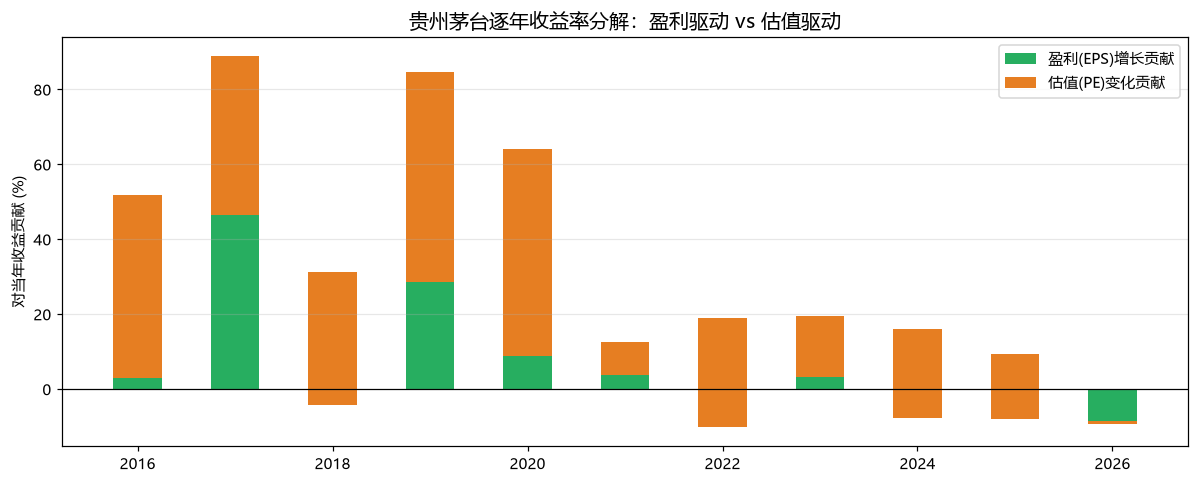

In [15]:
# 图4：逐年收益率分解（盈利贡献 vs 估值贡献，堆叠）
years = snap.index[1:]
e = snap['eps_ret'].values[1:] * 100
p = snap['pe_ret'].values[1:] * 100

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(years, e, width=0.5, label='盈利(EPS)增长贡献', color='#27ae60')
ax.bar(years, p, width=0.5, bottom=e, label='估值(PE)变化贡献', color='#e67e22')
ax.axhline(0, color='black', lw=0.8)
ax.set_title('贵州茅台逐年收益率分解：盈利驱动 vs 估值驱动', fontsize=13)
ax.set_ylabel('对当年收益贡献 (%)')
ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [16]:
# 风险收益统计：年化收益、年化波动、最大回撤、夏普(rf=0)
def max_drawdown(r):
    cum = (1 + r).cumprod()
    return (cum / cum.cummax() - 1).min()

def stats(r, name):
    r = r.dropna()
    ann_ret = r.mean() * 252
    ann_vol = r.std() * np.sqrt(252)
    sharpe = ann_ret / ann_vol          # 无风险利率近似取 0
    mdd = max_drawdown(r)
    return pd.Series({'年化收益': ann_ret, '年化波动': ann_vol,
                      '夏普(rf=0)': sharpe, '最大回撤': mdd}, name=name)

stat_tab = pd.DataFrame({
    '茅台': stats(price['ret'], '茅台'),
    '沪深300': stats(df_idx['ret'], '沪深300'),
})
stat_tab

,茅台,沪深300
年化收益,0.205534,0.039046
年化波动,0.297912,0.214774
夏普(rf=0),0.689914,0.181799
最大回撤,-0.550700,-0.466961


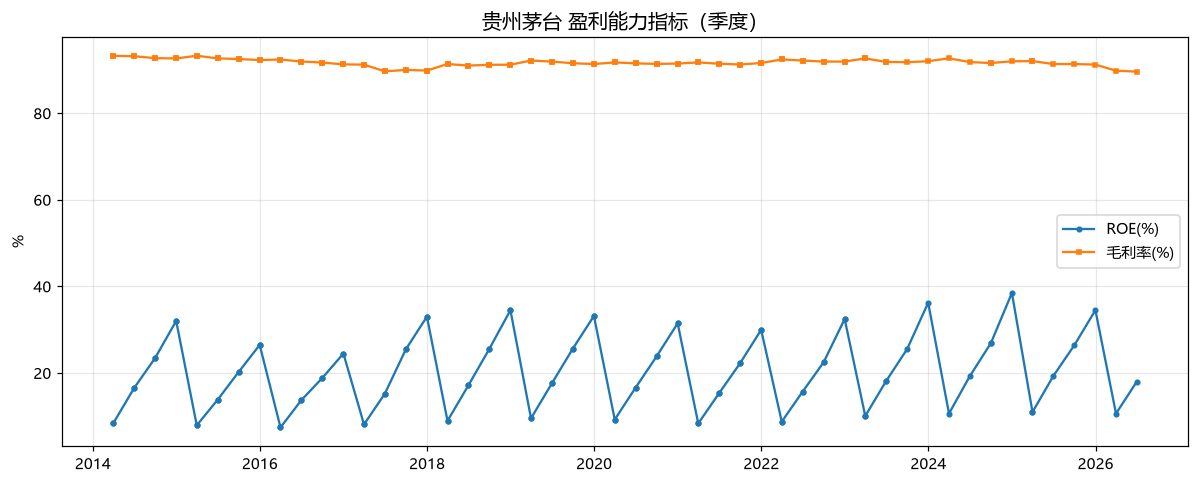

ROE 年度均值: 31.6%   毛利率年度均值: 91.5%


In [17]:
# 图5：基本面——ROE 与毛利率（季度）
fi = df_fina.set_index('end_date')
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(fi.index, fi['roe'], marker='o', ms=3, label='ROE(%)')
ax.plot(fi.index, fi['grossprofit_margin'], marker='s', ms=3, label='毛利率(%)')
ax.set_title('贵州茅台 盈利能力指标（季度）', fontsize=13)
ax.set_ylabel('%')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ann = fi[fi.index.month == 12]
print(f"ROE 年度均值: {ann['roe'].mean():.1f}%   毛利率年度均值: {ann['grossprofit_margin'].mean():.1f}%")

# 补充分析：让结论更扎实（增强可视化）

上面的分析已经回答了核心问题，但“业绩驱动”这个结论还可以说得更硬。下面再补几张图，把**公司到底赚没赚到钱**这件事摊开看：

- 图6：年度**营业收入与净利润**规模（这是 EPS 增长的根源）；
- 图7：**EPS 逐年增长**曲线（盈利驱动最直接的证据）；
- 图8：营收 / 净利润**同比增速**（看增长快不快）；
- 图9：**回撤曲线**（水下图，直观感受风险有多大）；
- 图10：**累计超额收益**曲线（跑赢大盘的幅度随时间怎么累积）；
- 图11：**PE 历史分布**（当前估值在历史上到底处于多低的位置）。

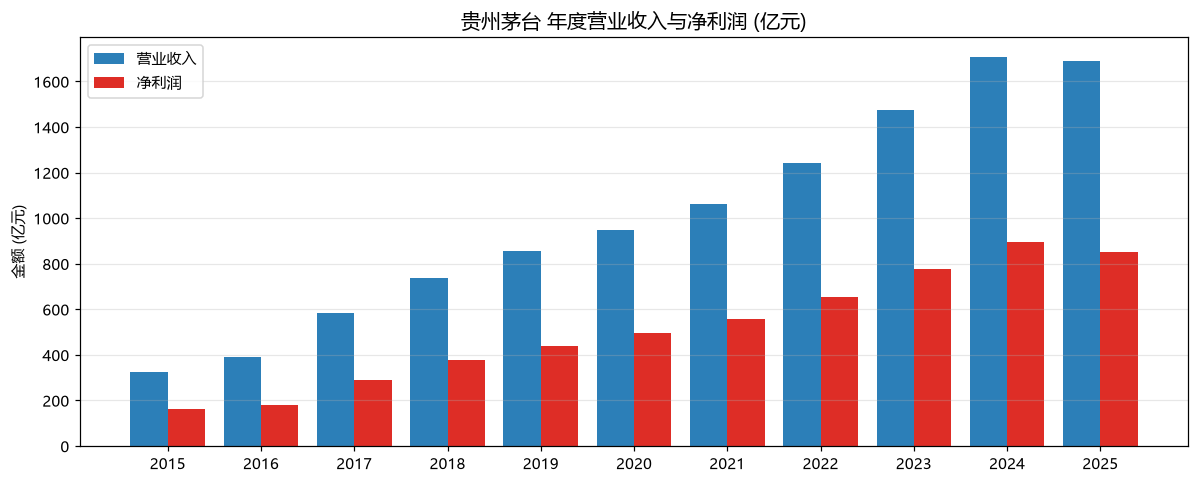

营收: 2015年 327亿 -> 2025年 1688亿 (年复合 17.9%)
净利润: 2015年 165亿 -> 2025年 853亿 (年复合 17.9%)


In [18]:
# 图6：年度营业收入与净利润（业绩成长全貌）
inc = df_income.copy()
inc['year'] = inc['end_date'].dt.year
inc_yr = inc[inc['end_date'].dt.month == 12].groupby('year').last()[['revenue', 'n_income']] / 1e8  # 元 -> 亿元
inc_yr = inc_yr[inc_yr.index >= 2015]
x = np.arange(len(inc_yr))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(x - 0.2, inc_yr['revenue'], width=0.4, color='#2c7fb8', label='营业收入')
ax.bar(x + 0.2, inc_yr['n_income'], width=0.4, color='#de2d26', label='净利润')
ax.set_xticks(x); ax.set_xticklabels(inc_yr.index)
ax.set_title('贵州茅台 年度营业收入与净利润 (亿元)', fontsize=13)
ax.set_ylabel('金额 (亿元)'); ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()
fy0, fy1 = inc_yr.index[0], inc_yr.index[-1]
rev_cagr = (inc_yr['revenue'].iloc[-1] / inc_yr['revenue'].iloc[0]) ** (1/(fy1-fy0)) - 1
ni_cagr  = (inc_yr['n_income'].iloc[-1] / inc_yr['n_income'].iloc[0]) ** (1/(fy1-fy0)) - 1
print(f"营收: {fy0}年 {inc_yr['revenue'].iloc[0]:.0f}亿 -> {fy1}年 {inc_yr['revenue'].iloc[-1]:.0f}亿 (年复合 {rev_cagr:.1%})")
print(f"净利润: {fy0}年 {inc_yr['n_income'].iloc[0]:.0f}亿 -> {fy1}年 {inc_yr['n_income'].iloc[-1]:.0f}亿 (年复合 {ni_cagr:.1%})")

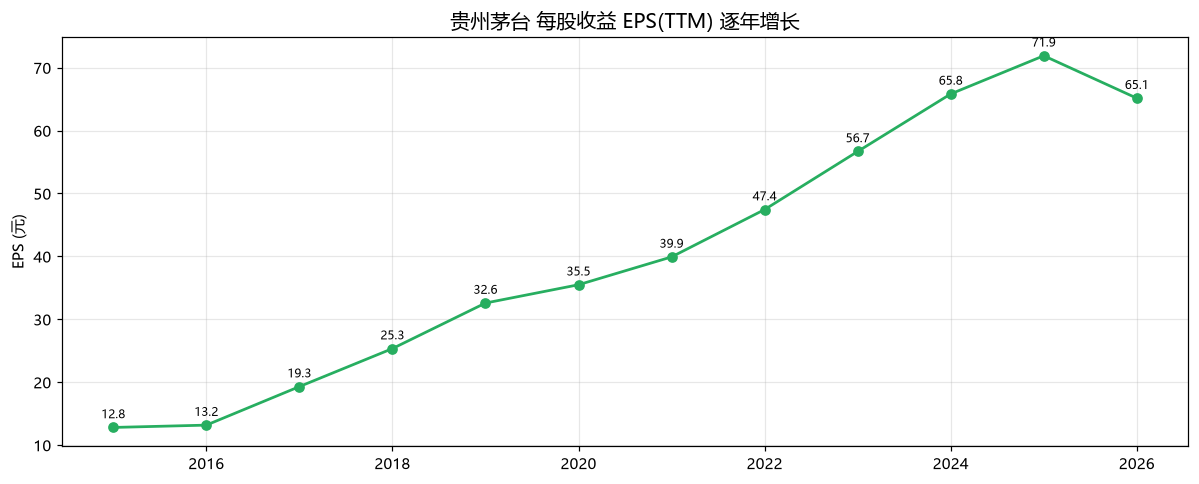

EPS(TTM): 12.8元 -> 65.1元，累计增长 409%


In [19]:
# 图7：EPS 逐年增长（盈利驱动的直接证据）
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(snap.index, snap['eps_ttm'], marker='o', color='#27ae60', lw=1.8)
for xi, yi in zip(snap.index, snap['eps_ttm']):
    ax.annotate(f'{yi:.1f}', (xi, yi), textcoords='offset points', xytext=(0, 6), ha='center', fontsize=8)
ax.set_title('贵州茅台 每股收益 EPS(TTM) 逐年增长', fontsize=13)
ax.set_ylabel('EPS (元)'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"EPS(TTM): {snap['eps_ttm'].iloc[0]:.1f}元 -> {snap['eps_ttm'].iloc[-1]:.1f}元，累计增长 {snap['eps_ttm'].iloc[-1]/snap['eps_ttm'].iloc[0]-1:.0%}")

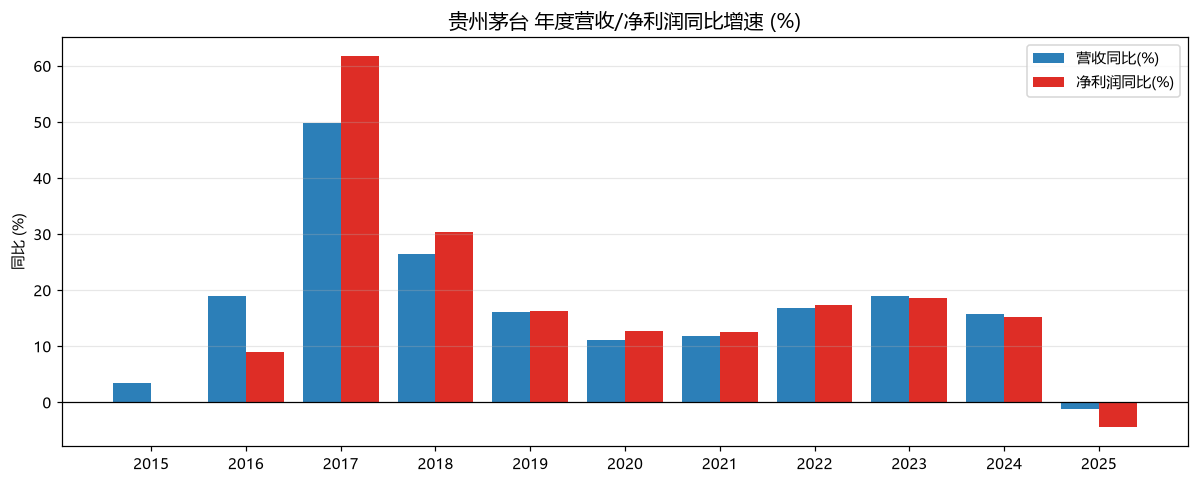

营收同比均值: 17.1%   净利润同比均值: 18.9%


In [20]:
# 图8：年度营收同比 / 净利润同比增速
fi2 = df_fina.copy(); fi2['year'] = fi2['end_date'].dt.year
yoy = fi2[fi2['end_date'].dt.month == 12].groupby('year').last()[['or_yoy']]
yoy = yoy[yoy.index >= 2015]
# 净利润同比由利润表年度净利润计算（fina_indicator 的 profit_yoy 本环境无权限）
inc = df_income.copy(); inc['year'] = inc['end_date'].dt.year
inc_yr8 = inc[inc['end_date'].dt.month == 12].groupby('year').last()[['n_income']] / 1e8
inc_yr8 = inc_yr8[inc_yr8.index >= 2015]
yoy['净利润同比'] = inc_yr8['n_income'].pct_change() * 100
x = np.arange(len(yoy))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(x - 0.2, yoy['or_yoy'], width=0.4, color='#2c7fb8', label='营收同比(%)')
ax.bar(x + 0.2, yoy['净利润同比'], width=0.4, color='#de2d26', label='净利润同比(%)')
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(yoy.index)
ax.set_title('贵州茅台 年度营收/净利润同比增速 (%)', fontsize=13)
ax.set_ylabel('同比 (%)'); ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()
print(f"营收同比均值: {yoy['or_yoy'].mean():.1f}%   净利润同比均值: {yoy['净利润同比'].mean():.1f}%")

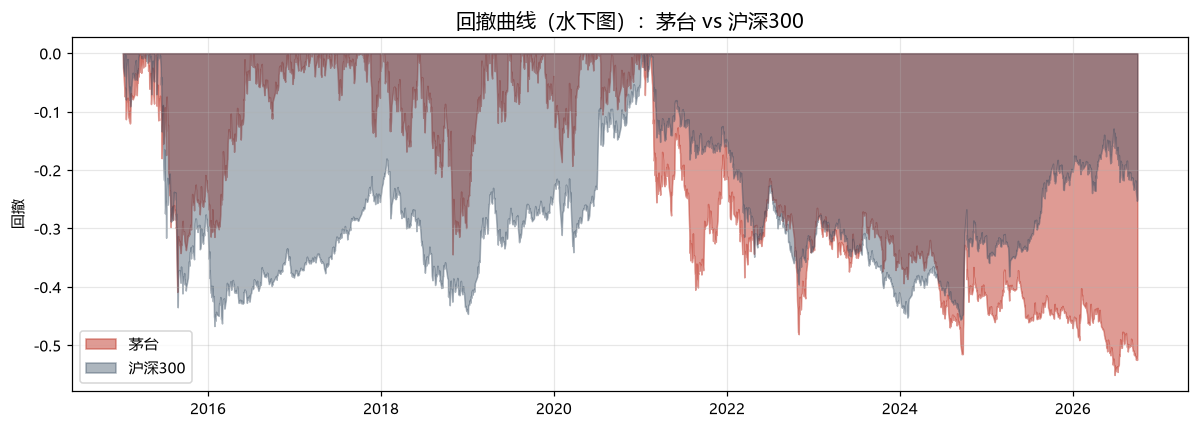

最大回撤  茅台: -55.1%   沪深300: -46.7%


In [21]:
# 图9：回撤曲线（水下图）——直观看风险
def dd_series(r):
    cum = (1 + r.dropna()).cumprod()
    return cum / cum.cummax() - 1
dd_m = dd_series(price['ret'])
dd_i = dd_series(df_idx['ret'])
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(dd_m.index, dd_m.values, 0, color='#c0392b', alpha=0.5, label='茅台')
ax.fill_between(dd_i.index, dd_i.values, 0, color='#34495e', alpha=0.4, label='沪深300')
ax.set_title('回撤曲线（水下图）：茅台 vs 沪深300', fontsize=13)
ax.set_ylabel('回撤'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"最大回撤  茅台: {dd_m.min():.1%}   沪深300: {dd_i.min():.1%}")

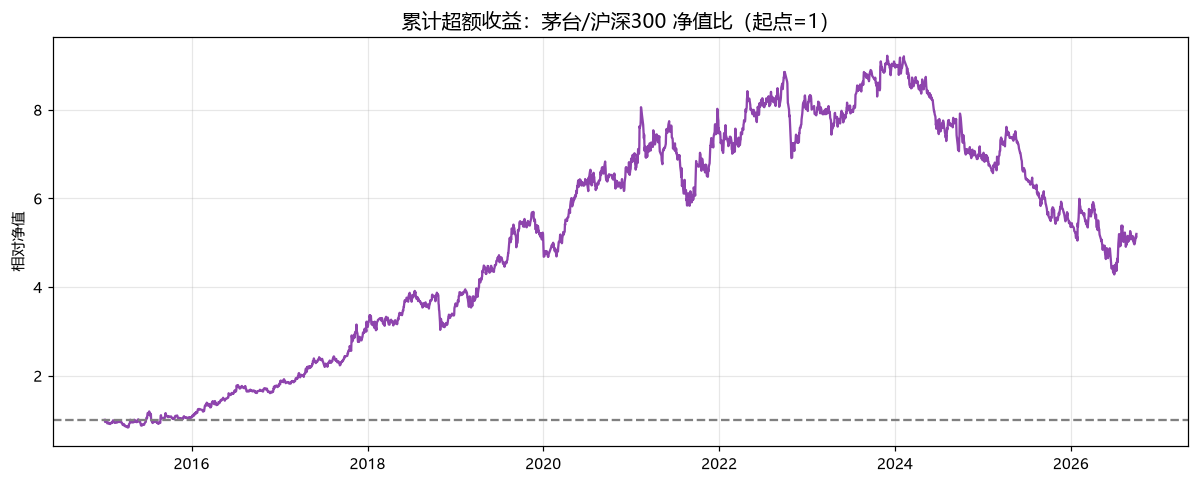

相对净值由 1 升至 5.19，即长期跑赢 419%


In [22]:
# 图10：累计超额收益（茅台/沪深300 净值比，起点=1）
excess = nv['茅台'] / nv['沪深300']
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(excess.index, excess.values, color='#8e44ad', lw=1.5)
ax.axhline(1, color='gray', ls='--')
ax.set_title('累计超额收益：茅台/沪深300 净值比（起点=1）', fontsize=13)
ax.set_ylabel('相对净值'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"相对净值由 1 升至 {excess.iloc[-1]:.2f}，即长期跑赢 {excess.iloc[-1]-1:.0%}")

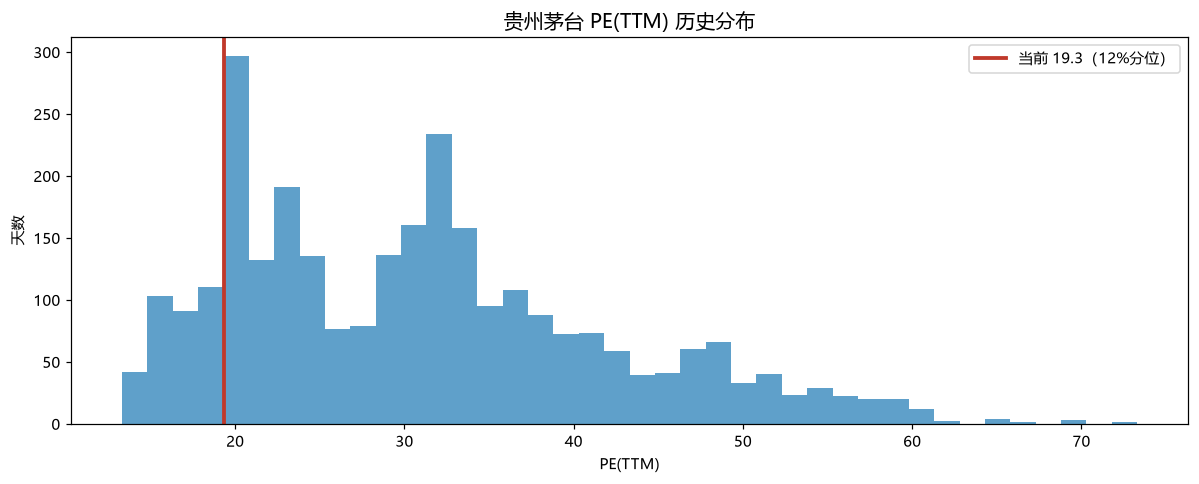

In [23]:
# 图11：PE(TTM) 历史分布直方图（当前估值分位）
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(pe.values, bins=40, color='#2980b9', alpha=0.75)
cur = pe.iloc[-1]
ax.axvline(cur, color='#c0392b', lw=2.5, label=f'当前 {cur:.1f}（{(pe<cur).mean()*100:.0f}%分位）')
ax.set_title('贵州茅台 PE(TTM) 历史分布', fontsize=13)
ax.set_xlabel('PE(TTM)'); ax.set_ylabel('天数'); ax.legend()
plt.tight_layout(); plt.show()

In [24]:
# ===== 关键结论数据汇总（供第五部分引用）=====
print("=" * 56)
print("关键结论数据汇总")
print(f"样本区间 : {price.index[0].date()} ~ {price.index[-1].date()}（{len(price)} 个交易日）")
print(f"股价累计涨幅 : {total_ret_m:.1%}")
print(f"沪深300累计涨幅 : {total_ret_i:.1%}")
print(f"相对沪深300超额收益 : {total_ret_m - total_ret_i:.1%}")
print(f"年化收益(茅台) : {stat_tab.loc['年化收益','茅台']:.1%}   波动: {stat_tab.loc['年化波动','茅台']:.1%}   最大回撤: {stat_tab.loc['最大回撤','茅台']:.1%}")
print(f"当前 PE(TTM) : {pe.iloc[-1]:.1f}   历史分位: {(pe < pe.iloc[-1]).mean()*100:.0f}%")
print(f"区间 EPS 倍数 : {eps_mult.iloc[-1]:.2f}x   区间 PE 倍数: {pe_mult.iloc[-1]:.2f}x")
ann = fi[fi.index.month == 12]
print(f"ROE(年度)均值: {ann['roe'].mean():.1f}%   毛利率(年度)均值: {ann['grossprofit_margin'].mean():.1f}%")
print("=" * 56)
# 业绩规模（补充，支撑“业绩驱动”结论）
inc = df_income.copy(); inc['year'] = inc['end_date'].dt.year
inc_yr = inc[inc['end_date'].dt.month == 12].groupby('year').last()[['revenue', 'n_income']] / 1e8
inc_yr = inc_yr[inc_yr.index >= 2015]
fy0, fy1 = inc_yr.index[0], inc_yr.index[-1]
rev_cagr = (inc_yr['revenue'].iloc[-1] / inc_yr['revenue'].iloc[0]) ** (1/(fy1-fy0)) - 1
ni_cagr  = (inc_yr['n_income'].iloc[-1] / inc_yr['n_income'].iloc[0]) ** (1/(fy1-fy0)) - 1
print(f"营收规模: {fy0} {inc_yr['revenue'].iloc[0]:.0f}亿 -> {fy1} {inc_yr['revenue'].iloc[-1]:.0f}亿 (CAGR {rev_cagr:.1%})")
print(f"净利润规模: {fy0} {inc_yr['n_income'].iloc[0]:.0f}亿 -> {fy1} {inc_yr['n_income'].iloc[-1]:.0f}亿 (CAGR {ni_cagr:.1%})")


关键结论数据汇总
样本区间 : 2015-01-05 ~ 2026-09-30（2855 个交易日）
股价累计涨幅 : 521.5%
沪深300累计涨幅 : 19.7%
相对沪深300超额收益 : 501.8%
年化收益(茅台) : 20.6%   波动: 29.8%   最大回撤: -55.1%
当前 PE(TTM) : 19.3   历史分位: 12%
区间 EPS 倍数 : 5.09x   区间 PE 倍数: 1.13x
ROE(年度)均值: 31.6%   毛利率(年度)均值: 91.5%
营收规模: 2015 327亿 -> 2025 1688亿 (CAGR 17.9%)
净利润规模: 2015 165亿 -> 2025 853亿 (CAGR 17.9%)


# 第五部分：研究结论与经验总结

## 研究结论

下面这些数字都是前面“关键结论数据汇总”那个 cell 真正跑出来的，围绕一开始的问题“茅台涨到底是业绩涨的还是估值涨的”：

1. **长期远远跑赢大盘**：2015 年初到 2026-09-30，茅台累计涨了约 **521.5%**，沪深300 只涨了 **19.7%**，多出来的 **501.8%** 就是它相对大盘的超额收益。
2. **这十年基本是“业绩涨”带起来的，估值几乎没怎么贡献**：以 2015 年底为基期，股价累计涨了约 **5.8 倍**，拆开看——盈利(EPS)增长了约 **5.1 倍**，而估值(PE)只变了 **1.13 倍**（基本没动）。也就是说，茅台这波长牛主要是公司一年比一年赚得多撑起来的，不是大家把估值炒上去的。期间 PE 在 2017–2021 年一度冲到 50–56 倍，但 2021 年之后又压回到约 19 倍，两头一抵几乎持平。
3. **现在估值处在历史低位**：当前 PE(TTM) 约 **19.3 倍**，位于历史 **12% 分位**，也就是比过去约 88% 的时间都便宜，比 2021 年高位安全不少。
4. **基本面确实硬**：毛利率长期在 90% 上下（年度均值 91.5%），ROE 年度口径长期维持 30% 左右；从营收看，2015 年以来营收、净利润都翻了好几倍（年复合增速见上方汇总），这就是 EPS 能一直涨的底气。
5. **但也不是没风险**：茅台年化波动约 **29.8%**、最大回撤约 **-55.1%**（2021 年高点跌下来那一段）。好公司也得买在好价格，追高一样会亏。

## 经验总结（作业心得）

这次作业对我来说收获挺大的。一开始我只是好奇“茅台为什么这么贵、凭什么一直涨”，真去用 tushare 拉了一堆数据之后才发现，分析一只股票真不能只盯着它的股价看。下面是我自己的一点体会：

1. **学会了用 tushare 取数**：流程是先 `ts.set_token()` 再 `pro = ts.pro_api()`。不同接口要的积分权限不一样，这次用到的 `daily`（日线）、`daily_basic`（估值/市值）、`fina_indicator`（财务比率）、`income`（利润表）、`index_daily`（指数）都是基础权限就能调的。其中 `daily_basic` 能直接拿到 PE、总市值这些估值数据，特别好用。
2. **学会了一个特别好用的拆解公式**：`价格 = 市盈率(PE) × 每股收益(EPS)`。把股价涨跌幅拆成“公司赚得多了(EPS 涨)”和“市场给的估值高了(PE 涨)”两部分，一眼就能看明白茅台这十年主要是靠业绩涨的，不是靠大家炒上去的。而且这两部分乘起来刚好等于股价涨幅，逻辑上很自洽。
3. **明白了要“双重对比”才靠谱**：一只股票自己涨多少说明不了问题，得跟大盘（沪深300）比才知道它是不是真的强；还要看它现在的 PE 在历史上算高还是算低，才知道当下贵不贵。只看一面很容易得出片面的结论。
4. **踩了几个小坑，也记下来了**：① 图表里的中文一开始显示成方块，后来在开头设置了 `Microsoft YaHei` / `SimHei` 字体就好了；② 取完数据一定要先按交易日排序、再把茅台和指数的日期对齐，不然算收益率会错位；③ 跑之前最好把数据存成 CSV，后面重跑或检查都方便。

总的来说，这次作业让我觉得课本里说的“价值投资”不是一句空话。茅台的例子让我看到，能长期拿得住的好公司，真的是靠一年比一年多赚钱撑起来的；但与此同时它的波动和回撤也不小，估值高位回落时照样能跌掉一半多——所以“好公司”和“好价格”还真得两样都占。